# DSO 607 HW4: numerical illustrations for (b)(iii)

These experiments illustrate the theoretical results; finite simulations do not replace the proofs. The mean is known to be zero, so every sample covariance below is **$X^\top X/n$, without centering**. All errors use the operator norm unless stated otherwise.

We examine (1) the null-space bound when $p>n$, (2) sample covariance and precision estimation for $\Sigma=I_p$, and (3) the sensitivity of inversion to perturbations. The notebook has no external data dependencies.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 6072026
rng_null = np.random.default_rng(SEED)
rng_sampling = np.random.default_rng(SEED + 1)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})
print("NumPy version:", np.__version__)
print("Random seed:", SEED)

NumPy version: 2.0.2
Random seed: 6072026


## 1. A unit vector in the null space, $p>n$

Take $n=60$, $p=100$, and $\Sigma=I_p$. A full singular-value decomposition supplies a unit vector $v$ in $\ker(X)=\ker(\widehat\Sigma)$. We check $\|(\widehat\Sigma-I_p)v\|_2=1$ and compare it with $\|\widehat\Sigma-I_p\|_{\rm op}$. Numerical rank uses a floating-point tolerance.

<ipython-input-1-9c44ee441063>:3: RuntimeWarning: divide by zero encountered in matmul
  S = X.T @ X / n
<ipython-input-1-9c44ee441063>:3: RuntimeWarning: overflow encountered in matmul
  S = X.T @ X / n
<ipython-input-1-9c44ee441063>:3: RuntimeWarning: invalid value encountered in matmul
  S = X.T @ X / n
<ipython-input-1-9c44ee441063>:11: RuntimeWarning: divide by zero encountered in matmul
  "||v||_2": np.linalg.norm(v), "||S v||_2": np.linalg.norm(S @ v),
<ipython-input-1-9c44ee441063>:11: RuntimeWarning: overflow encountered in matmul
  "||v||_2": np.linalg.norm(v), "||S v||_2": np.linalg.norm(S @ v),
<ipython-input-1-9c44ee441063>:11: RuntimeWarning: invalid value encountered in matmul
  "||v||_2": np.linalg.norm(v), "||S v||_2": np.linalg.norm(S @ v),
<ipython-input-1-9c44ee441063>:12: RuntimeWarning: divide by zero encountered in matmul
  "||(S-I)v||_2": np.linalg.norm((S - np.eye(p)) @ v),
<ipython-input-1-9c44ee441063>:12: RuntimeWarning: overflow encountered in matmul
  "||(

,value
n,6.000000e+01
p,1.000000e+02
numerical rank,6.000000e+01
zero eigenvalues (tolerance),4.000000e+01
||v||_2,1.000000e+00
||S v||_2,1.108126e-15
||(S-I)v||_2,1.000000e+00
||S-I||_op,3.990808e+00


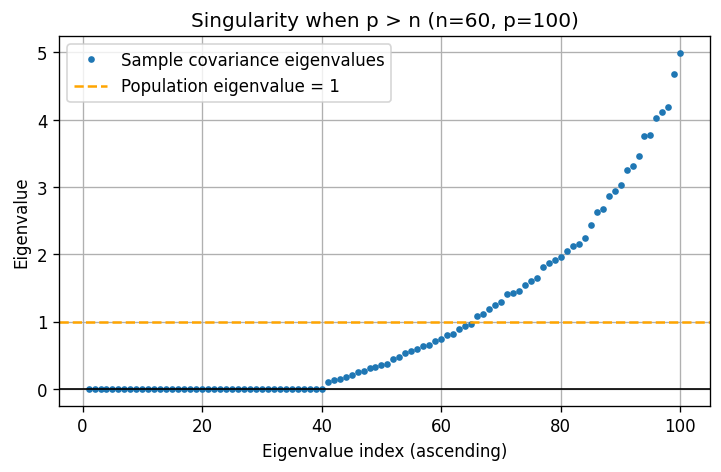

In [2]:
n, p = 60, 100
X = rng_null.standard_normal((n, p))
S = X.T @ X / n
_, singular_values, Vt = np.linalg.svd(X, full_matrices=True)
v = Vt[-1]
eigenvalues = np.linalg.eigvalsh(S)
tolerance = p * np.finfo(float).eps * np.max(np.abs(eigenvalues))
null_results = pd.DataFrame([{
    "n": n, "p": p, "numerical rank": np.count_nonzero(eigenvalues > tolerance),
    "zero eigenvalues (tolerance)": np.count_nonzero(np.abs(eigenvalues) <= tolerance),
    "||v||_2": np.linalg.norm(v), "||S v||_2": np.linalg.norm(S @ v),
    "||(S-I)v||_2": np.linalg.norm((S - np.eye(p)) @ v),
    "||S-I||_op": np.max(np.abs(eigenvalues - 1))
}])
display(null_results.T.rename(columns={0: "value"}))
assert np.linalg.norm(S @ v) < 1e-10
assert np.isclose(np.linalg.norm((S - np.eye(p)) @ v), 1)
assert np.max(np.abs(eigenvalues - 1)) >= 1 - 1e-10
fig, ax = plt.subplots()
ax.plot(np.arange(1, p+1), eigenvalues, '.', label="Sample covariance eigenvalues")
ax.axhline(0, color='black', linewidth=1)
ax.axhline(1, color='orange', linestyle='--', label="Population eigenvalue = 1")
ax.set(xlabel="Eigenvalue index (ascending)", ylabel="Eigenvalue", title="Singularity when p > n (n=60, p=100)")
ax.legend()
plt.show()

**Interpretation.** There are 40 zero eigenvalues, up to rounding. The chosen null vector yields error exactly 1 up to numerical precision. The full operator-norm error may exceed 1 because other directions can have larger errors. A numerical inverse should not be used here: the sample covariance is mathematically singular, even if a floating-point inversion routine happens to return a result.

## 2. Invertible samples can still give poor precision estimates

Fix $n=80$ and vary $p\leq n$. For each dimension, generate 30 independent datasets from $N_p(0,I_p)$. Since the true covariance and precision are both identity,
$$
\|\widehat\Sigma-I_p\|_{\rm op}=\max_j|\widehat\lambda_j-1|,
\qquad
\|\widehat\Sigma^{-1}-I_p\|_{\rm op}=\max_j|1/\widehat\lambda_j-1|.
$$
We evaluate these exact spectral formulas rather than explicitly forming an inverse. Report medians and the 10th--90th percentile range; inverse errors can have extreme outliers. These are descriptive finite-sample summaries, not confidence intervals.

<ipython-input-1-ff4313273c26>:6: RuntimeWarning: divide by zero encountered in matmul
  S = X.T @ X / n
<ipython-input-1-ff4313273c26>:6: RuntimeWarning: overflow encountered in matmul
  S = X.T @ X / n
<ipython-input-1-ff4313273c26>:6: RuntimeWarning: invalid value encountered in matmul
  S = X.T @ X / n


,median lambda_min,median condition_number,median covariance_error,median precision_error
p/n,,,,
0.10,0.508417,2.914708,0.528406,0.967127
0.50,0.100600,28.234060,1.723151,8.940512
0.80,0.016532,213.960303,2.483762,59.505954
0.95,0.001178,2990.556455,2.735254,847.995436
1.00,0.000056,70041.216534,2.802056,18735.369819


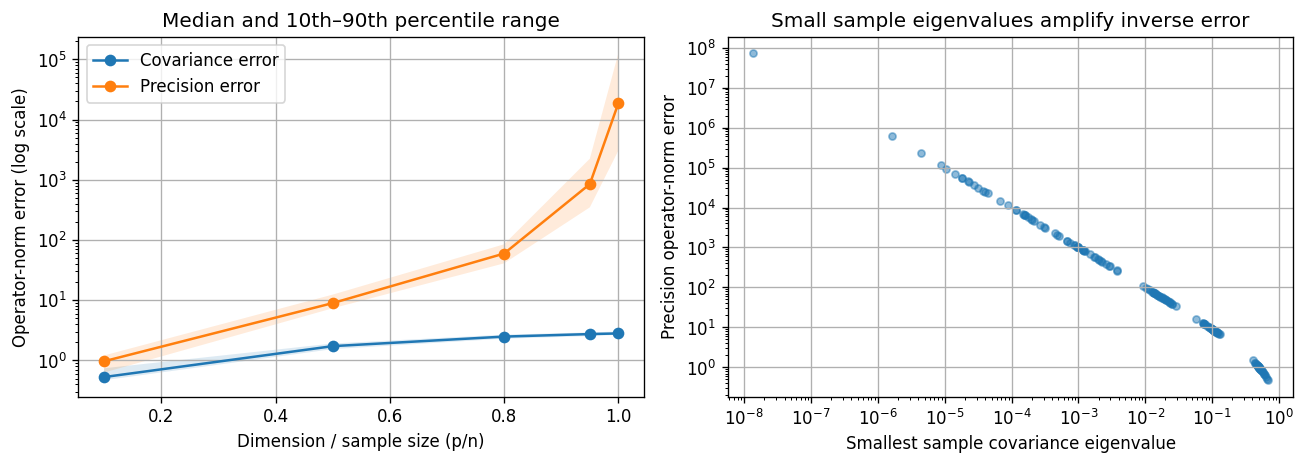

In [3]:
n, repetitions = 80, 30
records = []
for p in [8, 40, 64, 76, 80]:
    for rep in range(repetitions):
        X = rng_sampling.standard_normal((n, p))
        S = X.T @ X / n
        # Squared singular values are the eigenvalues of X.T @ X / n.
        # SVD avoids subtractive loss in extremely small eigenvalues.
        values = np.linalg.svd(X, compute_uv=False)**2 / n
        records.append({"p": p, "p/n": p/n,
                        "lambda_min": values.min(),
                        "condition_number": values.max()/values.min(),
                        "covariance_error": np.max(np.abs(values-1)),
                        "precision_error": np.max(np.abs(1/values-1))})
samples = pd.DataFrame(records)
summary = samples.groupby("p/n")[["lambda_min", "condition_number", "covariance_error", "precision_error"]].median()
display(summary.rename(columns=lambda x: "median " + x))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for column, label in [("covariance_error", "Covariance error"), ("precision_error", "Precision error")]:
    stats = samples.groupby("p/n")[column].quantile([0.1, 0.5, 0.9]).unstack()
    axes[0].plot(stats.index, stats[0.5], 'o-', label=label)
    axes[0].fill_between(stats.index, stats[0.1], stats[0.9], alpha=0.15)
axes[0].set(xlabel="Dimension / sample size (p/n)", ylabel="Operator-norm error (log scale)", yscale="log", title="Median and 10th–90th percentile range")
axes[0].legend()
axes[1].scatter(samples.lambda_min, samples.precision_error, alpha=0.5, s=18)
axes[1].set(xscale="log", yscale="log", xlabel="Smallest sample covariance eigenvalue", ylabel="Precision operator-norm error", title="Small sample eigenvalues amplify inverse error")
plt.tight_layout()
plt.show()

**Interpretation.** The sample covariance is invertible almost surely for every dimension in this experiment, including $p=n$. Nevertheless, small sample eigenvalues can produce large precision errors as $p$ approaches $n$. Here the population matrix is perfectly conditioned ($\Sigma=I_p$); instability arises in the estimated matrix. This experiment illustrates a sampling phenomenon, rather than proving an asymptotic limit or a lower bound for every estimator.

## 3. Absolute error amplification and relative numerical sensitivity

First take $\Sigma_\varepsilon=\varepsilon I_2$ and $\widetilde\Sigma_\varepsilon=2\varepsilon I_2$. Then covariance error is $\varepsilon$, while precision error is $1/(2\varepsilon)$. Your lower bound is attained exactly. Both matrices have condition number 1: large **absolute** inverse error need not imply poor **relative** numerical conditioning.

To illustrate poor conditioning separately, take $A_\varepsilon=\operatorname{diag}(1,\varepsilon)$ and perturb it by $E=\operatorname{diag}(0,\delta)$ with $\delta=10^{-10}$. Then
\[
\frac{\|E\|_{\rm op}}{\|A_\varepsilon\|_{\rm op}}=\delta,
\qquad
\frac{\|(A_\varepsilon+E)^{-1}-A_\varepsilon^{-1}\|_{\rm op}}
{\|A_\varepsilon^{-1}\|_{\rm op}}
=\frac{\delta}{\varepsilon+\delta}.
\]
This controlled perturbation measures sensitivity; it is not a direct experiment on a particular inversion algorithm's rounding error.

,epsilon,absolute covariance error (scaled identity),absolute precision error (scaled identity),"condition number (diag(1,epsilon))",relative input perturbation,relative inverse change
0,1.000000e-01,1.000000e-01,5.000000e+00,1.000000e+01,1.000000e-10,1.000000e-09
1,1.000000e-02,1.000000e-02,5.000000e+01,1.000000e+02,1.000000e-10,1.000000e-08
2,1.000000e-03,1.000000e-03,5.000000e+02,1.000000e+03,1.000000e-10,9.999999e-08
3,1.000000e-04,1.000000e-04,5.000000e+03,1.000000e+04,1.000000e-10,9.999990e-07
4,1.000000e-05,1.000000e-05,5.000000e+04,1.000000e+05,1.000000e-10,9.999900e-06
5,1.000000e-06,1.000000e-06,5.000000e+05,1.000000e+06,1.000000e-10,9.999000e-05
6,1.000000e-07,1.000000e-07,5.000000e+06,1.000000e+07,1.000000e-10,9.990010e-04
7,1.000000e-08,1.000000e-08,5.000000e+07,1.000000e+08,1.000000e-10,9.900990e-03
8,1.000000e-09,1.000000e-09,5.000000e+08,1.000000e+09,1.000000e-10,9.090909e-02
9,1.000000e-10,1.000000e-10,5.000000e+09,1.000000e+10,1.000000e-10,5.000000e-01


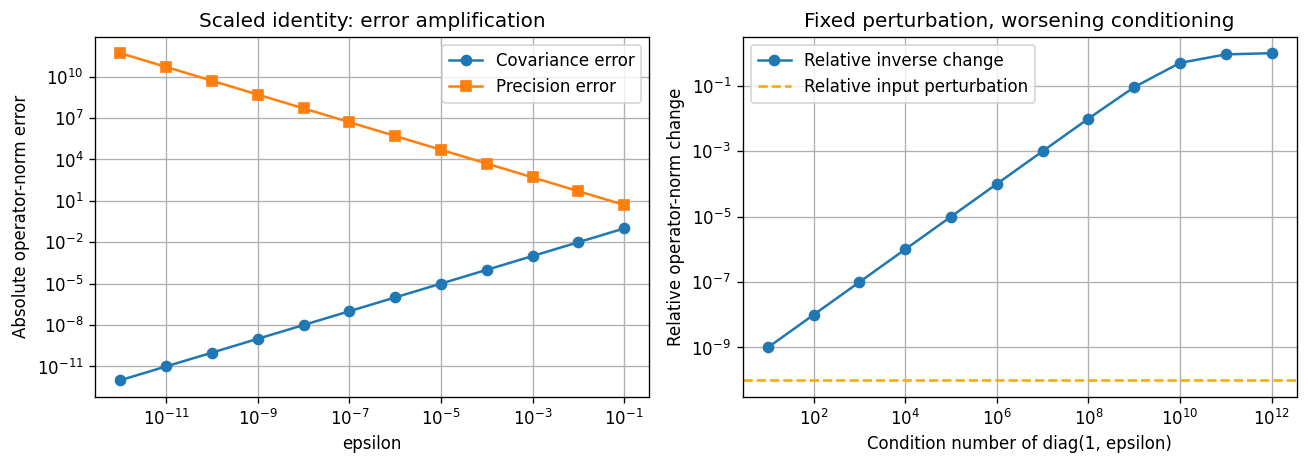

In [4]:
epsilons = np.logspace(-1, -12, 12)
delta = 1e-10
sensitivity = pd.DataFrame({
    "epsilon": epsilons,
    "absolute covariance error (scaled identity)": epsilons,
    "absolute precision error (scaled identity)": 1/(2*epsilons),
    "condition number (diag(1,epsilon))": 1/epsilons,
    "relative input perturbation": np.full(len(epsilons), delta),
    "relative inverse change": delta/(epsilons+delta)
})
display(sensitivity)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(epsilons, epsilons, 'o-', label="Covariance error")
axes[0].loglog(epsilons, 1/(2*epsilons), 's-', label="Precision error")
axes[0].set(xlabel="epsilon", ylabel="Absolute operator-norm error", title="Scaled identity: error amplification")
axes[0].legend()
axes[1].loglog(1/epsilons, delta/(epsilons+delta), 'o-', label="Relative inverse change")
axes[1].axhline(delta, linestyle='--', color='orange', label="Relative input perturbation")
axes[1].set(xlabel="Condition number of diag(1, epsilon)", ylabel="Relative operator-norm change", title="Fixed perturbation, worsening conditioning")
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretation.** The scaled-identity example shows that invertibility alone cannot bound absolute precision error in terms of small absolute covariance error uniformly over positive-definite matrices. The diagonal example shows that a fixed, tiny relative input perturbation can cause an order-one relative inverse change when the matrix is poorly conditioned.

Together, the experiments support the two conclusions of (b)(iii): singularity when $p>n$ prevents inversion, while invertibility when $p\leq n$ does not by itself guarantee precision accuracy or numerical stability.

## AI-use disclosure

This notebook was generated with assistance from OpenAI Codex for experiment design, code, and explanatory text. I reviewed the code and results.